In [44]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image

In [45]:
img_array = cv2.imread('IMG_4690.jpg')
print(img_array.shape)

# Row then Column, image take on IPhone then uploaded sent to discord and downloaded as .jpg
print(img_array[100,100])

(2880, 2160, 3)
[195 192 184]


## Image to Grayscale

In [46]:
# BGR since using openCV
weights = [.114,.587,.299]

gray_img = np.dot(img_array, weights).astype(np.uint8)

# Image Converted to grayscale does not have 3 channels
print(gray_img.shape)
# You can see that there is only one color value now
print(gray_img[100,100])


(2880, 2160)
189


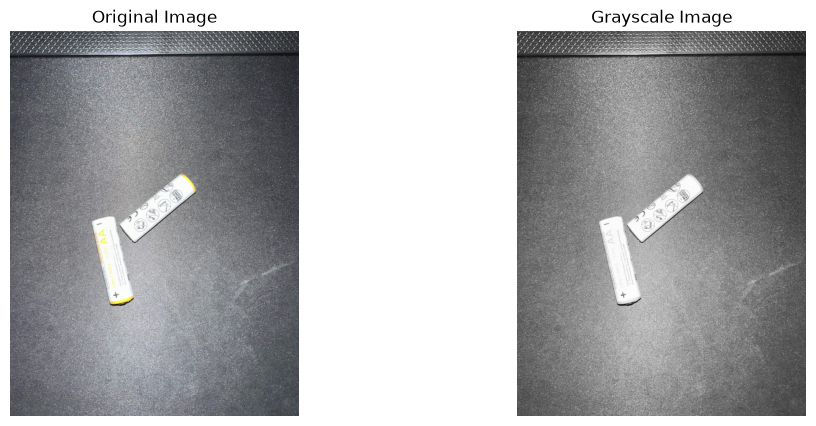

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(cv2.cvtColor(img_array, cv2.COLOR_BGR2RGB))
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(gray_img, cmap='gray', vmin=0, vmax=255)
ax[1].set_title("Grayscale Image")
ax[1].axis("off")

plt.show()

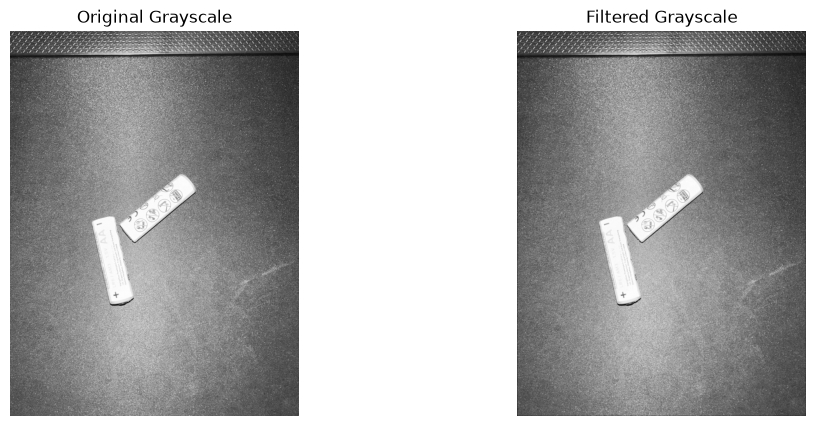

In [58]:
# Define a 3x3 averaging kernel
kernel = np.ones((3, 3)) / 9

# Get image dimensions
height, width = gray_img.shape

# Create an empty output image
filtered_img = np.zeros((height, width), dtype=np.uint8)

# Apply convolution
for y in range(1, height - 1):
    for x in range(1, width - 1):

        # Extract 3x3 neighborhood
        region = gray_img[y-1:y+2, x-1:x+2]

        # Multiply elementwise and sum
        value = np.sum(region * kernel)

        # Store result
        filtered_img[y, x] = np.uint8(value)

# Display results
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(gray_img, cmap='gray', vmin=0, vmax=255)
ax[0].set_title("Original Grayscale")

ax[1].imshow(filtered_img, cmap='gray', vmin=0, vmax=255)
ax[1].set_title("Filtered Grayscale")

for a in ax:
    a.axis('off')

plt.show()

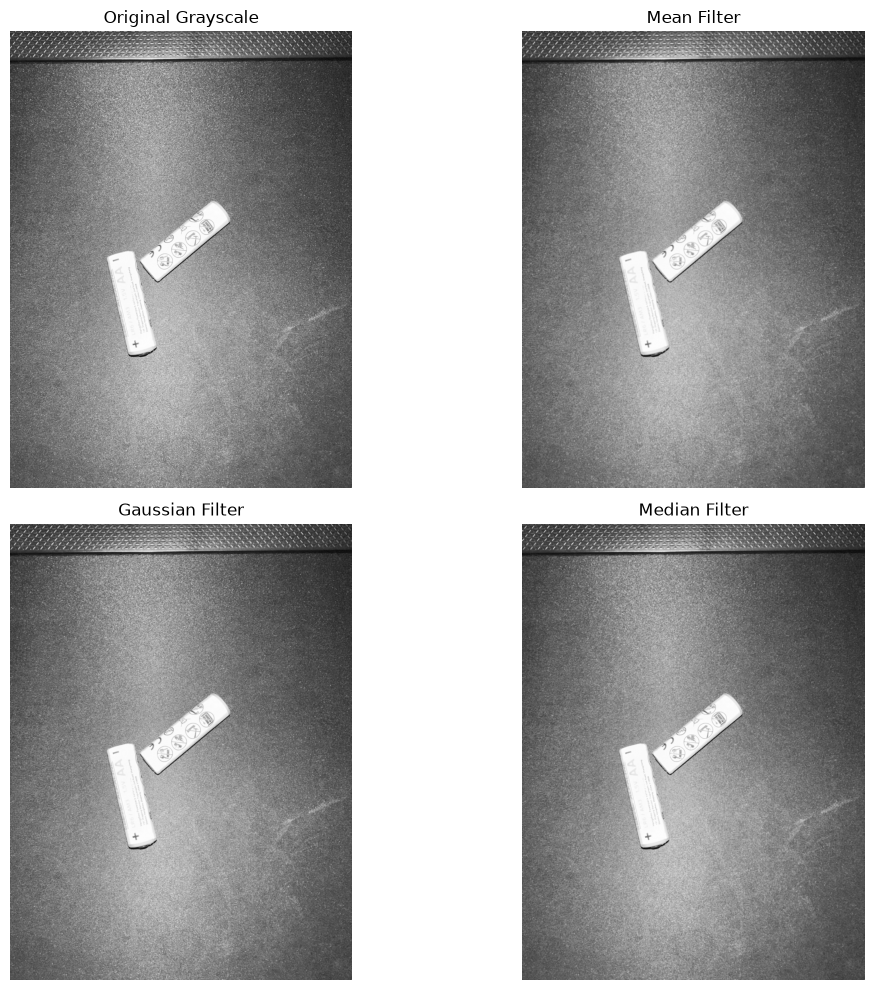

In [49]:
# Mean filter
mean_img = cv2.blur(gray_img, (5, 5))

# Gaussian filter
gaussian_img = cv2.GaussianBlur(gray_img, (5, 5), 1)

# Median filter
median_img = cv2.medianBlur(gray_img, 5)

# Create a 2x2 grid
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

images = [gray_img, mean_img, gaussian_img, median_img]
titles = ["Original Grayscale", "Mean Filter",
          "Gaussian Filter", "Median Filter"]

for axis, img, title in zip(ax.flat, images, titles):
    axis.imshow(img, cmap='gray', vmin=0, vmax=255)
    axis.set_title(title)
    axis.axis('off')

plt.tight_layout()
plt.show()

## Binary Representaion of the Image

### With Poor Thresholding

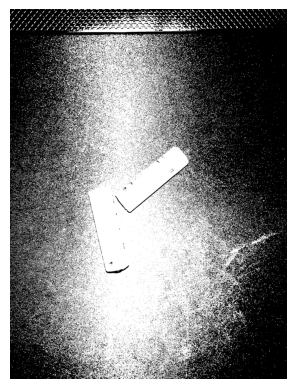

In [50]:
binary_mask = [255,0]

binary_img = np.zeros(gray_img.shape, dtype=np.uint8)


for i in range(img_array.shape[0]):
    for j in range(img_array.shape[1]):

        if gray_img[i,j] > 125:

            binary_img[i,j] = binary_mask[0]
        else:
            binary_img[i,j] = binary_mask[1]


plt.imshow(binary_img, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

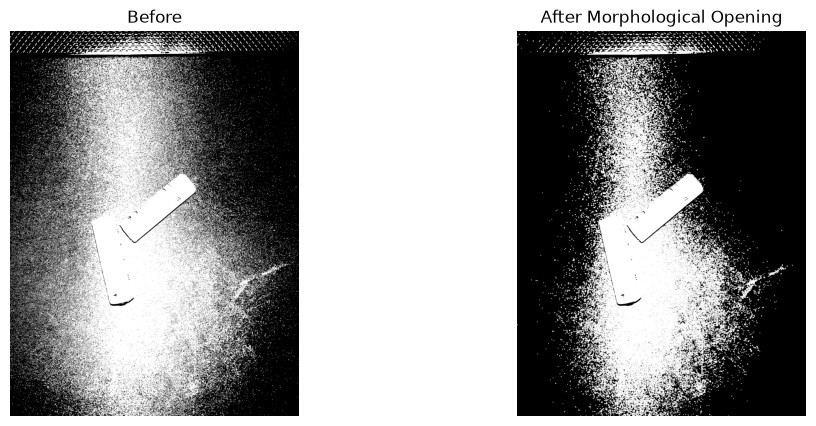

In [51]:
kernel = np.ones((5, 5), dtype=np.uint8)

cleaned_img = cv2.morphologyEx(
    binary_img,
    cv2.MORPH_OPEN,
    kernel
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(binary_img, cmap='gray')
ax[0].set_title("Before")

ax[1].imshow(cleaned_img, cmap='gray')
ax[1].set_title("After Morphological Opening")

for a in ax:
    a.axis("off")

plt.show()

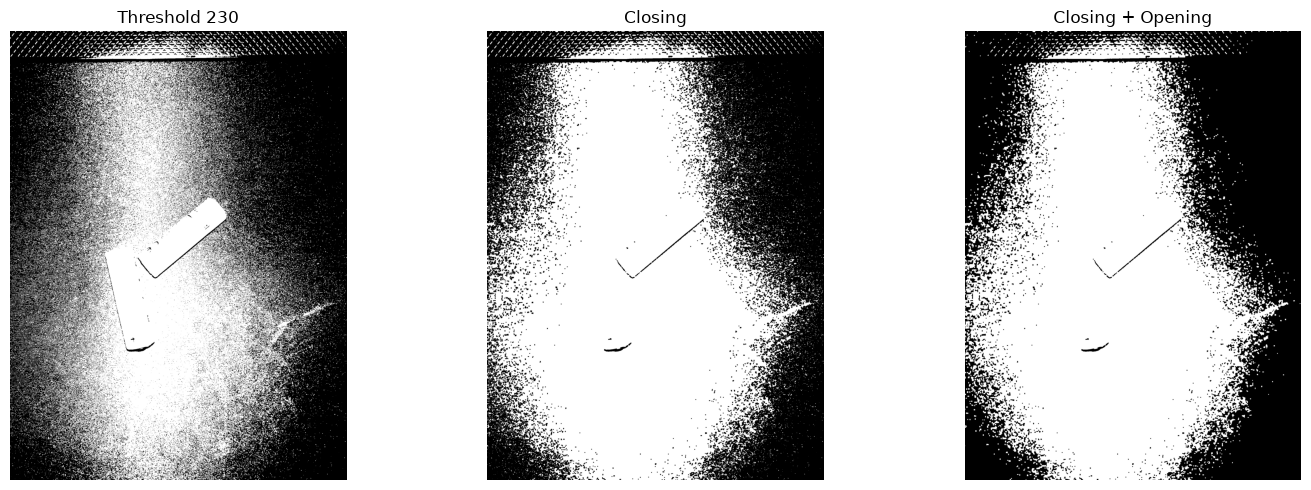

In [52]:
kernel = np.ones((5, 5), dtype=np.uint8)

# Fill small black gaps inside batteries
closed_img = cv2.morphologyEx(
    binary_img,
    cv2.MORPH_CLOSE,
    kernel
)

# Remove small isolated white noise
cleaned_img = cv2.morphologyEx(
    closed_img,
    cv2.MORPH_OPEN,
    kernel
)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

images = [binary_img, closed_img, cleaned_img]
titles = ["Threshold 230", "Closing", "Closing + Opening"]

for a, img, title in zip(ax, images, titles):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(title)
    a.axis('off')

plt.tight_layout()
plt.show()

#### Counting

In [53]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    cleaned_img,
    connectivity=8
)

min_area = 300  # Adjust for your image resolution
count = 0

for i in range(1, num_labels):  # Skip background
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= min_area:
        count += 1

print("Detected objects:", count)

Detected objects: 113


### With Better Thresholding

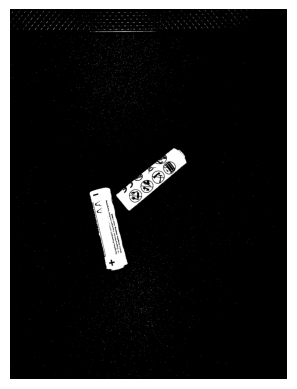

In [54]:
binary_mask = [255,0]

binary_img_2 = np.zeros(gray_img.shape, dtype=np.uint8)


for i in range(img_array.shape[0]):
    for j in range(img_array.shape[1]):

        if gray_img[i,j] > 230:

            binary_img_2[i,j] = binary_mask[0]
        else:
            binary_img_2[i,j] = binary_mask[1]


plt.imshow(binary_img_2, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

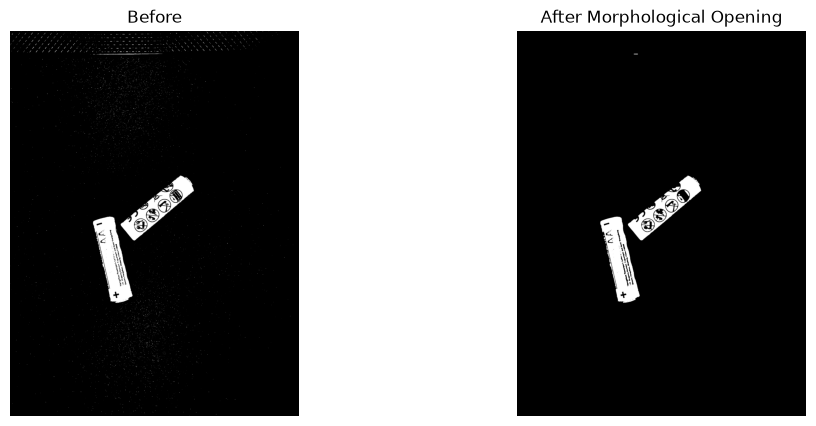

In [55]:
kernel = np.ones((5, 5), dtype=np.uint8)

cleaned_img = cv2.morphologyEx(
    binary_img_2,
    cv2.MORPH_OPEN,
    kernel
)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(binary_img_2, cmap='gray')
ax[0].set_title("Before")

ax[1].imshow(cleaned_img, cmap='gray')
ax[1].set_title("After Morphological Opening")

for a in ax:
    a.axis("off")

plt.show()

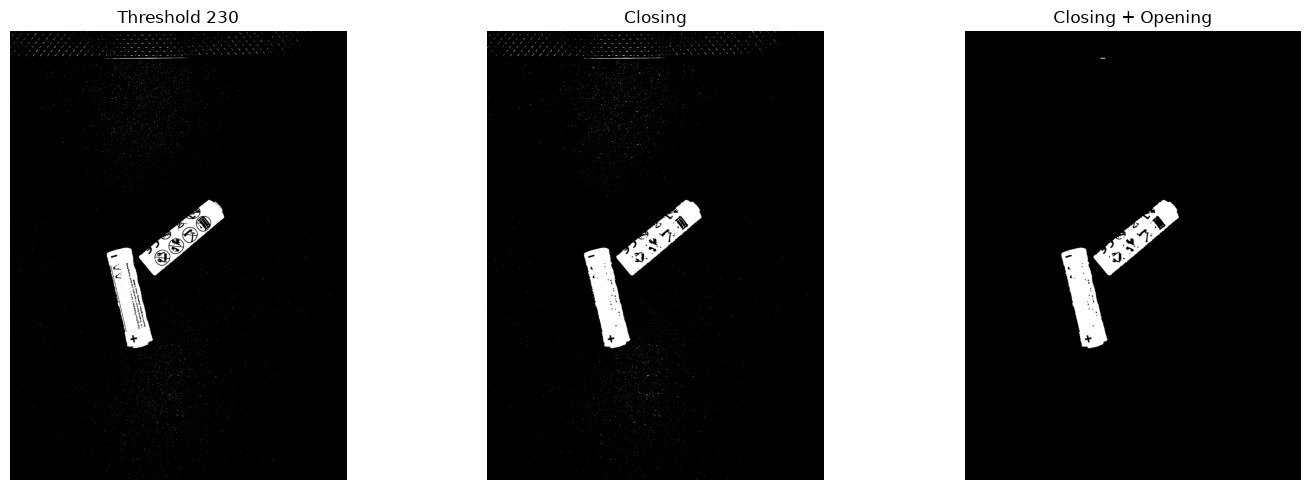

In [56]:
kernel = np.ones((5, 5), dtype=np.uint8)

# Fill small black gaps inside batteries
closed_img = cv2.morphologyEx(
    binary_img_2,
    cv2.MORPH_CLOSE,
    kernel
)

# Remove small isolated white noise
cleaned_img = cv2.morphologyEx(
    closed_img,
    cv2.MORPH_OPEN,
    kernel
)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

images = [binary_img_2, closed_img, cleaned_img]
titles = ["Threshold 230", "Closing", "Closing + Opening"]

for a, img, title in zip(ax, images, titles):
    a.imshow(img, cmap='gray', vmin=0, vmax=255)
    a.set_title(title)
    a.axis('off')

plt.tight_layout()
plt.show()

#### Counting

In [57]:
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    cleaned_img,
    connectivity=8
)

min_area = 300  # Adjust for your image resolution
count = 0

for i in range(1, num_labels):  # Skip background
    area = stats[i, cv2.CC_STAT_AREA]

    if area >= min_area:
        count += 1

print("Detected objects:", count)

Detected objects: 2
